# Massing, storeys, basements and party walls

Represent vertical diversity and contact assumptions without inventing terrain, overlapping solids or partial basements.

This is an executable lesson about representing building-stock diversity with EPSM Core. All dimensions are metric. The materials, use patterns and stock weights are explicit demonstration assumptions, not calibrated national statistics. Read each explanation before changing the code.

**How to use:** select the **EPSM Core Demo** kernel and Run All from a fresh kernel. Each notebook is independent; generated files go under `output/demo/`. Setup instructions and the complete learning path are in [the demo guide](../README.md).

**Prerequisites:** notebook environment; no EnergyPlus or weather required.

## Understanding the API in this lesson

A `BuildingPart` combines a footprint with elevation **boundaries**, including the roofline. `(0, 3, 6)` therefore describes two storeys, not three. `GeometrySpec(parts=...)` collects compatible parts and exposes conditioned area and volume properties.

`basement_depth_m` adds a full-footprint basement; `basement_conditioned` determines whether it belongs to the conditioned-area denominator. `PartyWall` declares reviewed contact on an existing facade ID. The height-exposure figure is especially useful here: an upper facade can be exposed even when a lower wing touches the same plan edge.

### Figure guide — Exposure changes above an adjoining lower wing

![Exposure changes above an adjoining lower wing; reference figure from EPSM documentation](../../docs/figures/geometry-height-exposure.svg)

**How to read this figure.** The lower wing ends at 6 m. Above it, the taller part has a newly exposed facade, so its perimeter subdivision can change by height. Physical slabs remain at actual storeys. This explains why a single plan outline or total height cannot describe all exposure in a multi-part building.

*Source: [EPSM geometry documentation](../../docs/geometry.md); [open the original figure](../../docs/figures/geometry-height-exposure.svg).*

### Before the first code cell

The setup cell finds the repository, imports the package and plotting tools, and creates a fresh `OUT` directory. `building()` and `geometry()` are **demo input factories**; `table()`, `plans()`, `bars()` and `preview()` are **presentation helpers**, not public `epsm_core` entry points. In particular, `preview()` already displays its output and returns no handle, avoiding duplicate widget display. The public specification and simulation calls remain visible in the lesson cells. Run the setup once per fresh kernel, then follow the cells in order.

In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / "src/epsm_core").is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
import json
from dataclasses import asdict
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from epsm_core import *
from demo.support.common import (building, geometry, epw, engine, workspace, table,
                                 plans, preview, bars, weather_frame, result_frame, result_plots)
from epsm_core.inspection import geometry_scene
OUT = workspace(Path.cwd().name)


## Describe unequal wings

Parts begin at common grade and may have different heights. Shared ownership seams and exposed upper walls have distinct physical meanings.

### Read the code and output

Each wing occupies 300 m² in plan. Two storeys in the low wing and four in the high wing give `300 × 2 + 300 × 4 = 1800 m²`. Adjacent parts do not overlap in positive plan area. The visual seam is not an instruction to add another physical exterior wall between the two parts.

Reference: [The same forms under different thermal partitions](../../docs/figures/geometry-zoning.svg). This linked documentation illustration is separate from the outputs computed below.

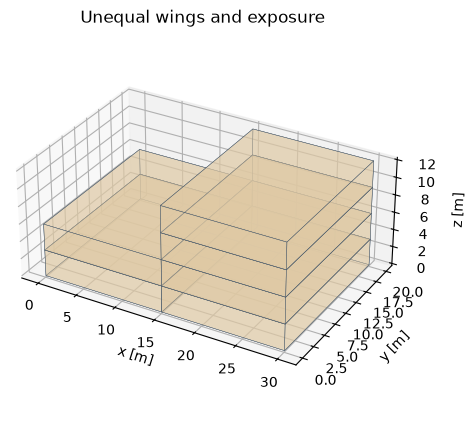

,part,floors,height_m
0,low,2,6.0
1,high,4,12.0


In [2]:
from shapely.geometry import box
parts = (BuildingPart(identifier="low",
                      footprint=Footprint(exterior=tuple(box(0,0,15,20).exterior.coords)),
                      storey_elevations_m=(0,3,6)),
         BuildingPart(identifier="high",
                      footprint=Footprint(exterior=tuple(box(15,0,30,20).exterior.coords)),
                      storey_elevations_m=(0,3,6,9,12)))
g = GeometrySpec(parts=parts)
assert g.conditioned_floor_area_m2 == 1800
preview(g, "Unequal wings and exposure")
t_parts = table([{"part": p.identifier, "floors": p.floors, "height_m": p.storey_elevations_m[-1]} for p in parts])

## Separate basement conditioning

The current basement spans the full footprint. Adding an unconditioned basement changes thermal boundaries; conditioning it also changes the area denominator.

### Read the code and output

An unconditioned basement changes the thermal path between occupied rooms and ground without increasing conditioned floor area. Conditioning it adds 600 m² in this example. Compare total energy and area-normalized energy separately whenever you change this flag, because both numerator and denominator may change.

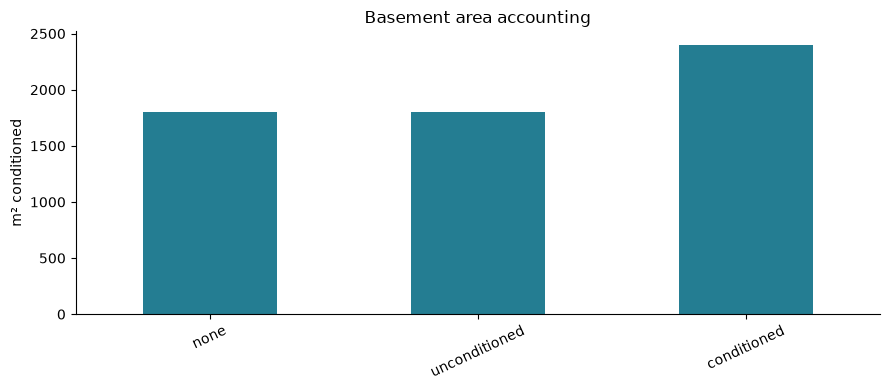

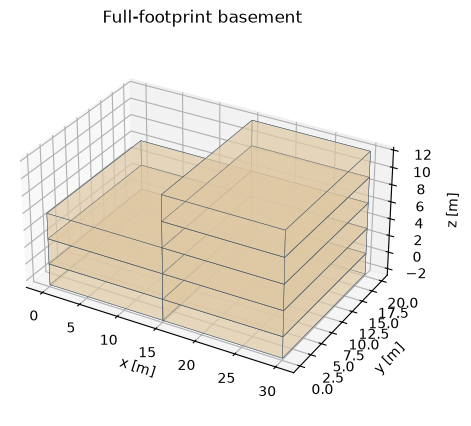

In [3]:
variants = {"none": g, "unconditioned": g.updated(basement_depth_m=2.5),
            "conditioned": g.updated(basement_depth_m=2.5, basement_conditioned=True)}
bars({k:v.conditioned_floor_area_m2 for k,v in variants.items()}, "m² conditioned", "Basement area accounting")
assert variants["conditioned"].conditioned_floor_area_m2 > g.conditioned_floor_area_m2
preview(variants["unconditioned"], "Full-footprint basement")

## Declare reviewed party-wall evidence

Touching a neighbour does not automatically imply a thermal party wall. Record contact, neighbour conditioning and the source of the assumption explicitly.

### Read the code and output

The helper `geometry()` creates a rectangular building with several facades. This cell selects just the first facade and assigns reviewed party-wall evidence to it. `contact_confirmed` and `neighbor_conditioning` express assumptions about physical contact; displaying a nearby `ContextBuilding` alone would only create shading.

,field,value
0,facade_id,main.r0.e0
1,neighbor_id,reviewed-neighbour
2,neighbor_conditioning,heated
3,contact_confirmed,True
4,assumption_source,demonstration reviewed contact


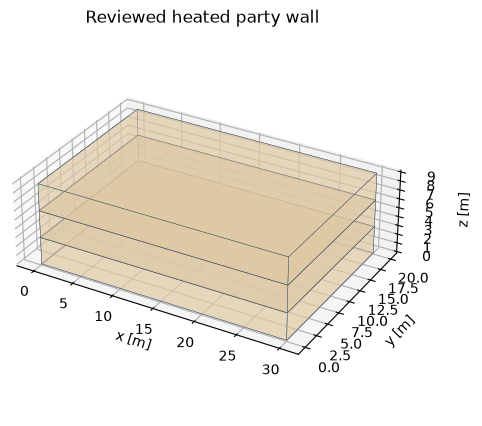

In [4]:
# Create a rectangular demo geometry, then select one of its facades for a reviewed party wall.
simple = geometry()
facade = simple.facades()[0]
party = PartyWall(facade_id=facade.facade_id,
                  neighbor_id="reviewed-neighbour",
                  neighbor_conditioning="heated",
                  contact_confirmed=True,
                  assumption_source="demonstration reviewed contact")
attached = simple.updated(party_walls=(party,))
table(party.model_dump())
preview(attached, "Reviewed heated party wall")

## Interpretation and next experiment

Height and basement assumptions affect both load and floor-area normalization. Keep contact evidence separate from geometric adjacency.

For a stock study, retain the inputs, provenance and acceptance decisions with every result. A successful geometry preview does not establish simulation validity or predictive accuracy. Change one assumption at a time before combining measures, and report rejected or substituted cases alongside accepted cases.